# Validasi Data & Deteksi Anomali Sensor Pembangkit Listrik

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/power-plant-anomaly/blob/main/power_plant_anomaly.ipynb)

Notebook ini menjawab tiga pertanyaan tentang data sensor pembangkit listrik tenaga uap selama 2022:
1. Apakah angka di data konsisten dengan rumus fisikanya?
2. Bisakah efisiensi boiler dan turbin diprediksi dari sensor?
3. Kapan sensor menunjukkan nilai tidak wajar, dan seberapa andal detektornya?

## 1. Data

Data CSV diunduh dari Google Drive: 50.091 baris, satu baris per 10 menit, Januari–Desember 2022. Kolom dibagi tiga:
- **target**: efisiensi HP turbine dan efisiensi boiler;
- **turunan**: angka yang *dihitung* dari sensor lewat rumus (entalpi, heat rate, dsb.);
- **sensor**: 40 besaran yang diukur langsung (suhu, tekanan, aliran, emisi, beban).

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

CSV = 'industrial_dataset.csv'
if not os.path.exists(CSV):
    import gdown
    gdown.download(id='1B89CtLiDWSVutzxSLESP7O9XWwqh9mQX', output=CSV, quiet=True)
df = pd.read_csv(CSV, parse_dates=['Timestamp']).sort_values('Timestamp').reset_index(drop=True)

TARGET = ['HP Turbine eff (%)', 'Boiler Eff (%)']
TURUNAN = ['Entalphy inlet MS (kj/kg)', 'Entropi Inlet MS (Kj/Kg (Deg C))', 'Entalphy Cold Reheat (kj/kg)',
           'Entalphy Isentropis Cold Reheat (kj/kg)', 'ΔP aktual (Kj/Kg)', 'ΔHP isentropis (Kj/Kg)',
           'APH Leakage (%)', 'Corrected Flue Gas Out Temperature (°C)', 'APH Effectiveness (%)',
           'Energy Input From Boiler (Kcal/h)', 'NTHR (Kcal/Kwh)', 'NPHR (Kcal/Kwh)']
SENSOR = [c for c in df.columns if c not in ['Timestamp', *TARGET, *TURUNAN]]

fmt = lambda x, d=2: f'{round(x, d) + 0:,.{d}f}'.translate(str.maketrans(',.', '.,'))  # format angka Indonesia
os.makedirs('images', exist_ok=True)

## 2. Validasi: apakah angka di data masuk akal?

Sebelum membuat model, kita pastikan datanya bisa dipercaya. Ada tiga jenis cek:
- **Rumus**: kolom turunan harus sama dengan hasil rumusnya (toleransi 0,1%). Contohnya, efisiensi HP turbine = penurunan entalpi aktual ÷ penurunan entalpi isentropis × 100.
- **Fisik**: hubungan dasar harus terpenuhi di setiap baris. Contohnya, beban netto lebih kecil dari beban bruto.
- **Keterkaitan**: besaran yang secara fisik saling bergantung harus berkorelasi. Contohnya, makin besar aliran uap, makin besar listrik yang dihasilkan.

Cek rumus dan fisik **Lulus** bila terpenuhi di ≥ 99% baris. Cek keterkaitan Lulus bila korelasi Spearman ρ ≥ 0,5.

In [2]:
h_ms, dp, dhs = df['Entalphy inlet MS (kj/kg)'], df['ΔP aktual (Kj/Kg)'], df['ΔHP isentropis (Kj/Kg)']
rumus = {  # cek: (nilai di data, nilai dari rumus)
    'ΔP aktual = h_MS − h_CRH': (dp, h_ms - df['Entalphy Cold Reheat (kj/kg)']),
    'ΔH isentropis = h_MS − h_CRH,s': (dhs, h_ms - df['Entalphy Isentropis Cold Reheat (kj/kg)']),
    'η HP = ΔP ÷ ΔH isentropis × 100': (df['HP Turbine eff (%)'], dp / dhs * 100),
    'NTHR = energi input ÷ Nett Load': (df['NTHR (Kcal/Kwh)'], df['Energy Input From Boiler (Kcal/h)'] / (df['Nett Load (MW)'] * 1e3)),
    'NPHR = NTHR ÷ η boiler': (df['NPHR (Kcal/Kwh)'], df['NTHR (Kcal/Kwh)'] / (df['Boiler Eff (%)'] / 100)),
}
fisik = {
    'Nett Load < Gross Load': df['Nett Load (MW)'] < df['Gross Load (MW)'],
    'Suhu uap utama: turbin ≤ boiler': df['Main steam temperature (turbine side) (℃)'] <= df['Main steam temperature (boiler side) (℃)'],
    'Interval 10 menit, tanpa missing': df['Timestamp'].diff().fillna(pd.Timedelta('10min')).eq(pd.Timedelta('10min')) & df.notna().all(axis=1),
}
keterkaitan = {
    'Main steam flow ↔ Gross Load': ('Main steam flow (t/h)', 'Gross Load (MW)'),
    'Coal Flow ↔ Gross Load': ('Coal Flow (t/h)', 'Gross Load (MW)'),
    'Gross Load ↔ Nett Load': ('Gross Load (MW)', 'Nett Load (MW)'),
}
rho = df.drop(columns='Timestamp').corr(method='spearman').abs()
rho_maks = rho.mask(np.eye(len(rho), dtype=bool)).max().max()

validasi = pd.DataFrame(
    [('Rumus', k, np.isclose(a, b, rtol=1e-3).mean(), 0.99) for k, (a, b) in rumus.items()]
    + [('Fisik', k, m.mean(), 0.99) for k, m in fisik.items()]
    + [('Keterkaitan', k, df[a].corr(df[b], method='spearman'), 0.5) for k, (a, b) in keterkaitan.items()]
    + [('Keterkaitan', '|ρ| tertinggi dari semua pasangan kolom', rho_maks, 0.5)],
    columns=['Jenis', 'Cek', 'Nilai', 'Batas'])
validasi['Status'] = np.where(validasi['Nilai'] >= validasi['Batas'], 'Lulus', 'Gagal')
validasi.style.format({'Nilai': lambda v: fmt(v, 3), 'Batas': lambda v: fmt(v, 2)}).hide(axis='index')

Jenis,Cek,Nilai,Batas,Status
Rumus,ΔP aktual = h_MS − h_CRH,"0,101","0,99",Gagal
Rumus,"ΔH isentropis = h_MS − h_CRH,s","0,124","0,99",Gagal
Rumus,η HP = ΔP ÷ ΔH isentropis × 100,"0,116","0,99",Gagal
Rumus,NTHR = energi input ÷ Nett Load,"0,065","0,99",Gagal
Rumus,NPHR = NTHR ÷ η boiler,"0,066","0,99",Gagal
Fisik,Nett Load < Gross Load,"1,000","0,99",Lulus
Fisik,Suhu uap utama: turbin ≤ boiler,"0,997","0,99",Lulus
Fisik,"Interval 10 menit, tanpa missing","1,000","0,99",Lulus
Keterkaitan,Main steam flow ↔ Gross Load,"-0,002","0,50",Gagal
Keterkaitan,Coal Flow ↔ Gross Load,"0,002","0,50",Gagal


**Temuan.** Semua cek fisik lulus: Nett < Gross di 100% baris, interval rapi, tanpa missing. Tetapi semua cek rumus gagal. η HP hanya cocok dengan ΔP ÷ ΔH isentropis di 11,6% baris, dan NTHR hanya di 6,5%.

Sensor yang seharusnya bergerak bersama juga tidak berkorelasi, misalnya Main steam flow ↔ Gross Load (ρ = −0,002). Korelasi tertinggi dari 1.431 pasangan kolom hanya 0,023. Artinya setiap kolom berubah sendiri-sendiri, ciri data sintetis yang dibangkitkan per kolom, bukan rekaman pembangkit nyata.

## 3. Cek sinyal: bisakah efisiensi diprediksi dari sensor?

Model *gradient boosting* dilatih untuk menebak efisiensi dari 40 sensor. Hasilnya dibandingkan dengan *baseline* yang selalu menebak rata-rata.
- **Skema uji:** `TimeSeriesSplit` (5 fold). Model selalu dilatih di periode lebih awal dan diuji di periode sesudahnya, sehingga tidak ada informasi dari masa depan.
- **Cara membaca R²:** R² = 1 berarti tebakan sempurna. R² ≤ 0 berarti model tidak lebih baik dari menebak rata-rata.
- **Baris terakhir sengaja memakai kolom turunan.** Kolom ini dihitung dari target itu sendiri (*data leakage*). Pada data yang sehat, R²-nya akan mendekati 1.

In [3]:
cv = TimeSeriesSplit(n_splits=5)
r2 = lambda model, X, y: cross_val_score(model, X, y, cv=cv, scoring='r2').mean()
hgb = HistGradientBoostingRegressor(random_state=0)
sinyal = pd.DataFrame({y: {
    'Baseline (rata-rata)': r2(DummyRegressor(), df[SENSOR], df[y]),
    'Boosting, 40 sensor': r2(hgb, df[SENSOR], df[y]),
    'Boosting, + kolom turunan (leakage)': r2(hgb, df.drop(columns=['Timestamp', y]), df[y]),
} for y in TARGET})
sinyal.style.format(lambda v: fmt(v, 3))

,HP Turbine eff (%),Boiler Eff (%)
Baseline (rata-rata),"-0,001","0,000"
"Boosting, 40 sensor","-0,025","-0,025"
"Boosting, + kolom turunan (leakage)","-0,029","-0,028"


**Temuan.** Semua R² ≤ 0, bahkan ketika kolom turunan ikut dipakai. Ini sejalan dengan hasil validasi: kolom-kolomnya memang tidak saling terhubung. Karena itu notebook tidak melanjutkan ke tuning model atau SHAP, sebab model apa pun di data ini hanya akan mencocokkan kebetulan.

## 4. Deteksi anomali sensor

Setiap sensor diubah menjadi **robust z-score**: (nilai − median) ÷ (1,4826 × MAD), dengan MAD = median simpangan absolut. Median dan MAD tidak terseret oleh nilai ekstrem, jadi anomali tidak "menyamarkan" dirinya sendiri.

Satu baris ditandai anomali bila ada sensor dengan |z| > 4,5, dan sensor itulah penyebabnya. Baris anomali yang berurutan digabung menjadi satu **event**.

Pendekatan per sensor dipilih karena dua alasan: gangguan nyata seperti sensor rusak atau lonjakan biasanya muncul di satu atau dua sensor, dan metode ini tidak membutuhkan label.

In [4]:
BATAS_Z = 4.5
def robust_z(X):
    med = np.median(X, axis=0)
    return (X - med) / (1.4826 * np.median(np.abs(X - med), axis=0))

X = df[SENSOR].to_numpy()
Z = robust_z(X)
j = np.abs(Z).argmax(axis=1)
z_maks = Z[np.arange(len(Z)), j]
anomali = np.abs(z_maks) > BATAS_Z

a = pd.DataFrame({'Timestamp': df['Timestamp'], 'Sensor': np.array(SENSOR)[j], 'z': z_maks})[anomali]
a['Event'] = a['Timestamp'].diff().ne(pd.Timedelta('10min')).cumsum()  # baris berurutan = satu event
event = a.groupby('Event').agg(Mulai=('Timestamp', 'first'), Durasi_menit=('z', lambda z: 10 * len(z)),
                               Sensor=('Sensor', lambda s: s.mode()[0]), z_ekstrem=('z', lambda z: z[z.abs().idxmax()]))
event.style.format({'Mulai': '{:%d-%m-%Y %H:%M}', 'z_ekstrem': lambda v: fmt(v, 2)}).hide(axis='index')

Mulai,Durasi_menit,Sensor,z_ekstrem
01-01-2022 10:20,40,SO2 (mg/m3),"-4,73"
01-01-2022 13:00,10,Opacity (%),"-4,78"
04-01-2022 18:20,10,Superheater desuperheating water flow (t/h),"4,51"
08-01-2022 18:10,10,Dust (mg/m3),"-4,61"
25-01-2022 00:00,10,Coal Flow (t/h),"-4,57"
08-02-2022 07:30,10,Feedwater flow (t/h),"-4,58"
22-02-2022 15:50,10,HHV (Kcal/Kg),"-4,73"
28-04-2022 00:20,10,Pressure (Kpa),"4,87"
04-09-2022 16:50,10,O2 in APH (%),"-4,66"
28-09-2022 08:10,10,Cold Reheat Pressure (Mpa),"4,51"


**Temuan.** Sebanyak 17 baris (0,03% data) ditandai, terbagi menjadi 13 event. Event terpanjang adalah SO2 yang turun tajam selama 40 menit pada 1 Januari 2022 pukul 10:20, sedangkan event lainnya berlangsung 10–20 menit di sensor yang berbeda-beda.

Jumlah ini setara dengan yang diharapkan dari kebetulan: P(|z| > 4,5) ≈ 6,8 × 10⁻⁶ × 40 sensor × 50.091 baris ≈ 14 baris. Jadi pada data ini event lebih tepat dibaca sebagai nilai ekstrem acak, bukan gangguan operasi.

## 5. Kalibrasi detektor

Data ini tidak punya label anomali. Karena itu detektor diuji dengan **anomali buatan yang posisinya kita ketahui**: 1% baris acak diberi lonjakan sebesar k × simpangan baku pada 1–3 sensor.
- **Recall**: persentase lonjakan buatan yang tertangkap.
- **Precision**: persentase tanda anomali yang memang lonjakan buatan.

Detektor layak dipakai bila precision tinggi di semua ukuran lonjakan dan recall naik seiring besarnya lonjakan.

In [5]:
rng = np.random.default_rng(42)
def uji(k):
    Xs, benar = X.copy(), np.zeros(len(X), bool)
    for i in rng.choice(len(X), len(X) // 100, replace=False):
        kol = rng.choice(X.shape[1], rng.integers(1, 4), replace=False)
        Xs[i, kol] += rng.choice([-1, 1], len(kol)) * k * X[:, kol].std(axis=0)
        benar[i] = True
    tanda = (np.abs(robust_z(Xs)) > BATAS_Z).any(axis=1)
    return (tanda & benar).sum() / benar.sum(), (tanda & benar).sum() / tanda.sum()

K = [3, 4, 5, 6]
kalibrasi = pd.DataFrame([uji(k) for k in K], index=pd.Index(K, name='Lonjakan (× σ)'), columns=['Recall', 'Precision'])
kalibrasi.style.format(lambda v: fmt(v, 3))

,Recall,Precision
Lonjakan (× σ),,
3,"0,110","0,764"
4,"0,506","0,941"
5,"0,852","0,962"
6,"0,980","0,968"


**Temuan.** Untuk lonjakan ≥ 4σ, precision ≥ 0,94, artinya hampir setiap tanda adalah gangguan sungguhan. Recall naik dari 0,11 (3σ) ke 0,98 (6σ). Lonjakan ≥ 5σ hampir selalu tertangkap, sedangkan lonjakan 3σ sulit dibedakan dari variasi normal.

Ini batas yang wajar untuk detektor tanpa label. Ambang 4,5 bisa diturunkan bila menangkap gangguan kecil lebih penting daripada menghindari alarm palsu.

## 6. Ringkasan visual

Dua slide 16:9 disimpan di `images/`:
- **Slide 1:** hasil 12 cek validasi (hijau = lulus, merah = gagal), plus contoh efisiensi di data yang tidak mengikuti rumusnya.
- **Slide 2:** skor anomali harian sepanjang 2022 dan hasil uji detektor dengan lonjakan buatan.

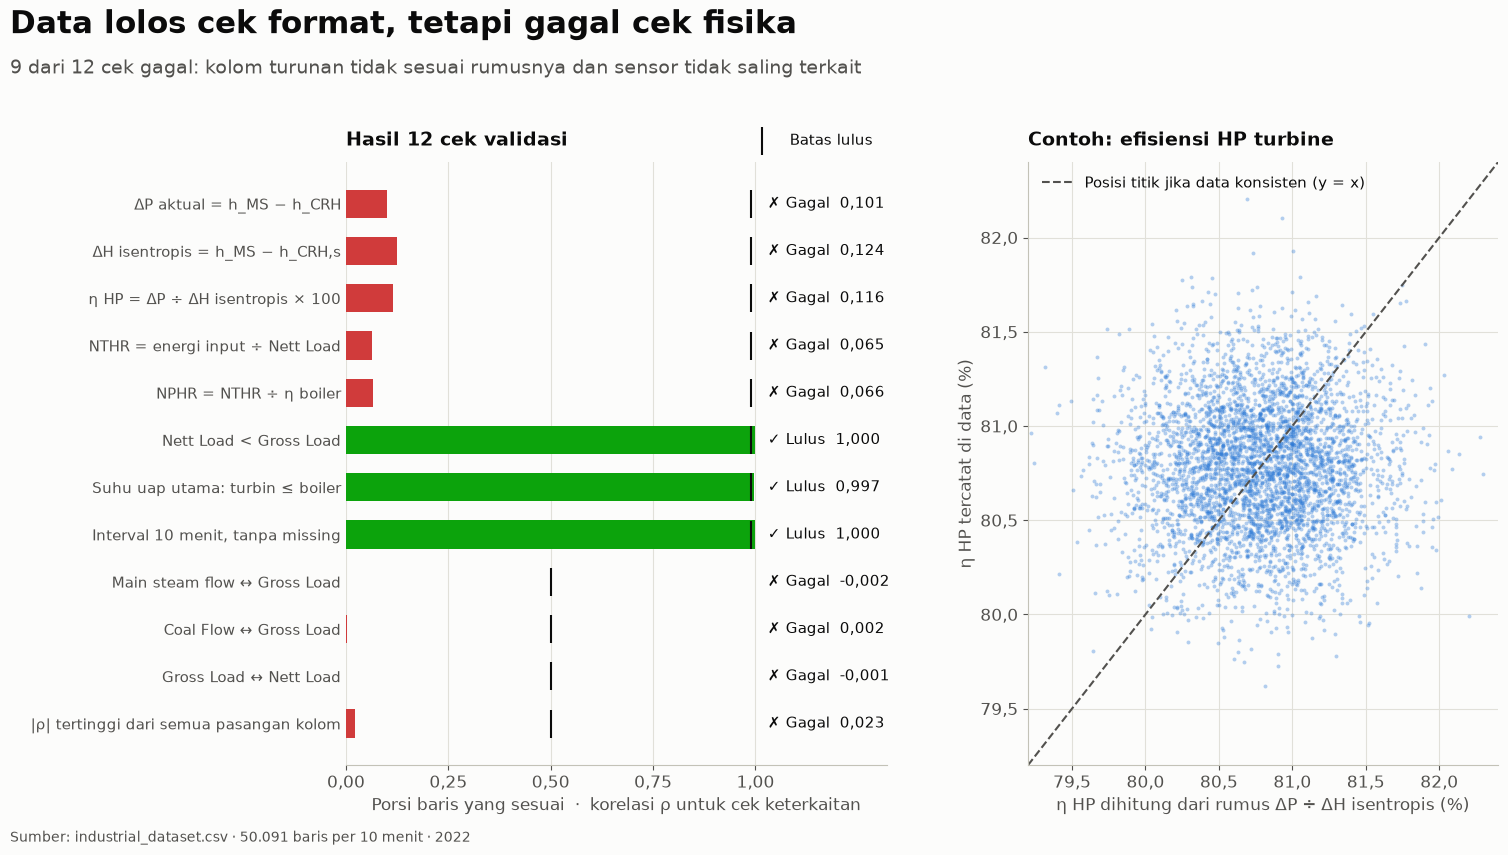

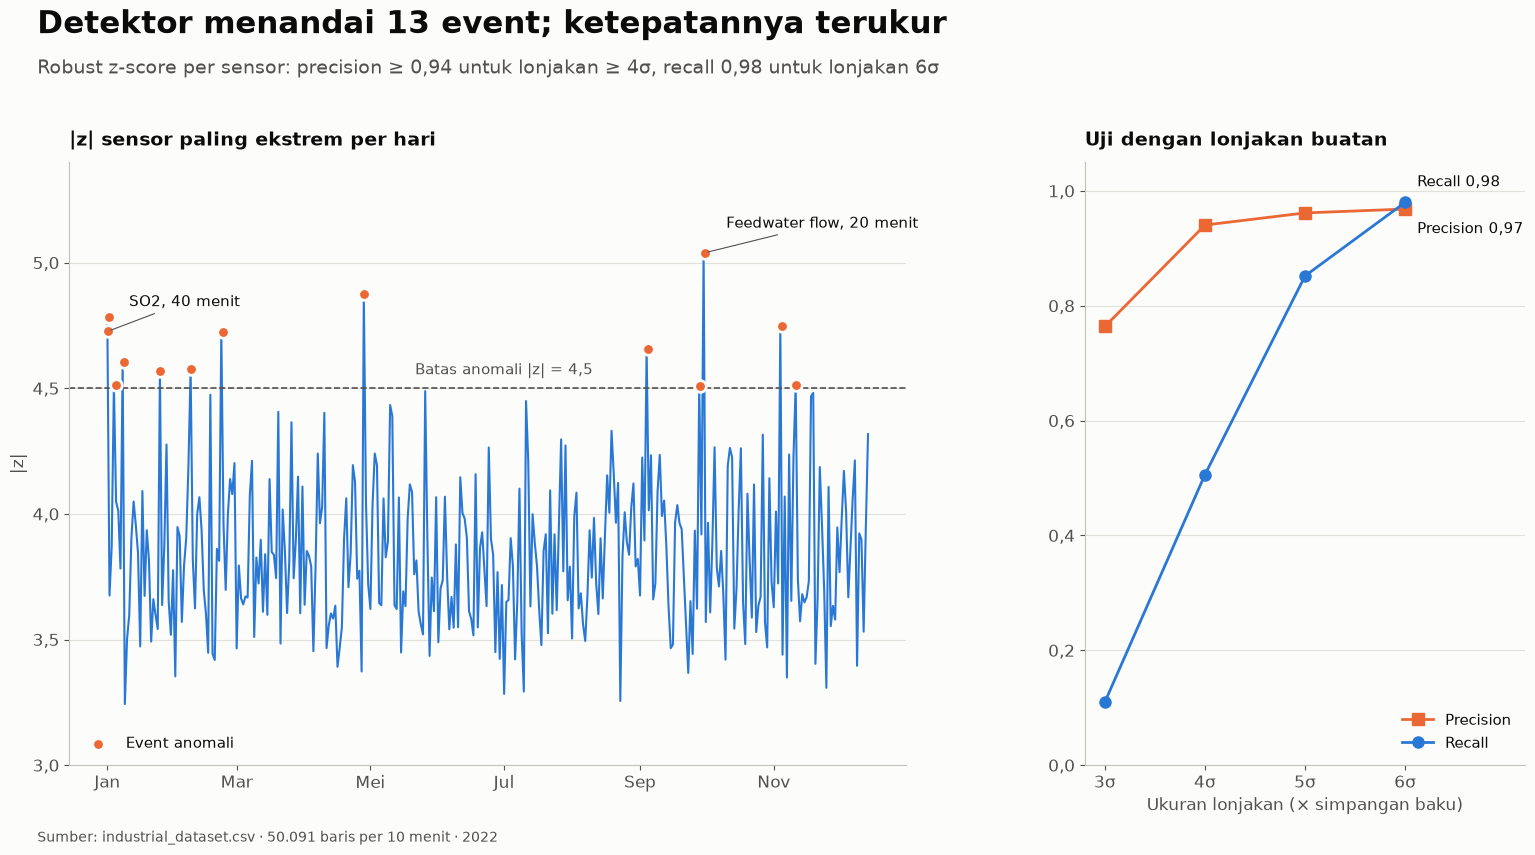

In [6]:
INK, INK2, GRID, AXIS, SURF = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BIRU, ORANYE, LULUS, GAGAL = '#2a78d6', '#eb6834', '#0ca30c', '#d03b3b'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'font.size': 12, 'text.color': INK,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.edgecolor': AXIS,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 14,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 12})
angka = lambda d: FuncFormatter(lambda v, _: fmt(v, d))
BULAN = FuncFormatter(lambda v, _: 'Jan Feb Mar Apr Mei Jun Jul Agu Sep Okt Nov Des'.split()[mdates.num2date(v).month - 1])

def slide(judul, sub, left=.06, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(16, 9), **kw)
    fig.text(.04, .95, judul, fontsize=22, fontweight='bold', va='top')
    fig.text(.04, .895, sub, fontsize=14, color=INK2, va='top')
    fig.text(.04, .025, 'Sumber: industrial_dataset.csv · 50.091 baris per 10 menit · 2022', fontsize=10, color=INK2)
    fig.subplots_adjust(left=left, right=.97, top=.78, bottom=.11, wspace=.28)
    return fig, axes

# Slide 1: scorecard validasi + bukti rumus
fig, (ax1, ax2) = slide('Data lolos cek format, tetapi gagal cek fisika',
    f'{(validasi.Status == "Gagal").sum()} dari {len(validasi)} cek gagal: kolom turunan tidak sesuai rumusnya dan sensor tidak saling terkait',
    left=.25, gridspec_kw={'width_ratios': [1.15, 1]})
v = validasi[::-1].reset_index(drop=True)
warna = np.where(v.Status == 'Lulus', LULUS, GAGAL)
ax1.barh(v.index, v.Nilai.clip(0, 1), height=.6, color=warna)
ax1.scatter(v.Batas, v.index, marker='|', s=400, color=INK, zorder=3, label='Batas lulus')
for i, r in v.iterrows():
    ax1.text(1.03, i, f"{'✓' if r.Status == 'Lulus' else '✗'} {r.Status}  {fmt(r.Nilai, 3)}", va='center', fontsize=11)
ax1.set_yticks(v.index, v.Cek, fontsize=11)
ax1.tick_params(axis='y', length=0)
ax1.set(xlim=(0, 1.32), xticks=[0, .25, .5, .75, 1], title='Hasil 12 cek validasi')
ax1.set_xlabel('Porsi baris yang sesuai  ·  korelasi ρ untuk cek keterkaitan')
ax1.xaxis.set_major_formatter(angka(2)); ax1.grid(axis='x', color=GRID, lw=.8); ax1.set_axisbelow(True)
ax1.spines['left'].set_visible(False)
ax1.legend(loc='lower right', bbox_to_anchor=(1, 1), frameon=False, fontsize=11)

eta, eta_rumus = rumus['η HP = ΔP ÷ ΔH isentropis × 100']
s = df.sample(4000, random_state=0).index
ax2.scatter(eta_rumus[s], eta[s], s=8, alpha=.35, color=BIRU, linewidths=0)
lim = [79.2, 82.4]
ax2.plot(lim, lim, color=INK2, ls='--', lw=1.5, label='Posisi titik jika data konsisten (y = x)')
ax2.legend(loc='upper left', frameon=False, fontsize=11)
ax2.set(xlim=lim, ylim=lim, title='Contoh: efisiensi HP turbine',
        xlabel='η HP dihitung dari rumus ΔP ÷ ΔH isentropis (%)', ylabel='η HP tercatat di data (%)')
ax2.xaxis.set_major_formatter(angka(1)); ax2.yaxis.set_major_formatter(angka(1))
ax2.grid(color=GRID, lw=.8); ax2.set_axisbelow(True)
fig.savefig('images/01_validasi.png', dpi=150); plt.show()

# Slide 2: skor anomali harian + kalibrasi
fig, (ax1, ax2) = slide('Detektor menandai 13 event; ketepatannya terukur',
    f'Robust z-score per sensor: precision ≥ {fmt(kalibrasi.loc[4:, "Precision"].min(), 2)} untuk lonjakan ≥ 4σ, '
    f'recall {fmt(kalibrasi.loc[6, "Recall"], 2)} untuk lonjakan 6σ',
    gridspec_kw={'width_ratios': [1.9, 1]})
harian = pd.Series(np.abs(z_maks), index=df['Timestamp']).resample('D').max()
ax1.plot(harian.index, harian, color=BIRU, lw=1.5)
ax1.axhline(BATAS_Z, color=INK2, ls='--', lw=1.2)
ax1.text(pd.Timestamp('2022-07-01'), BATAS_Z + .04, f'Batas anomali |z| = {fmt(BATAS_Z, 1)}', ha='center', va='bottom', fontsize=11, color=INK2)
ax1.scatter(event.Mulai, event.z_ekstrem.abs(), s=70, color=ORANYE, edgecolor=SURF, linewidth=2, zorder=3, label='Event anomali')
for _, e in event.nlargest(2, 'Durasi_menit').iterrows():
    ax1.annotate(f"{e.Sensor.split(' (')[0]}, {e.Durasi_menit} menit", xy=(e.Mulai, abs(e.z_ekstrem)),
                 xytext=(15, 18), textcoords='offset points', fontsize=11, color=INK,
                 arrowprops=dict(arrowstyle='-', color=INK2, lw=.8))
ax1.set(ylim=(3, 5.4), title='|z| sensor paling ekstrem per hari', ylabel='|z|')
ax1.xaxis.set_major_formatter(BULAN); ax1.yaxis.set_major_formatter(angka(1))
ax1.grid(axis='y', color=GRID, lw=.8); ax1.set_axisbelow(True)
ax1.legend(loc='lower left', frameon=False, fontsize=11)

for kol, warna_garis, mk, dy in [('Precision', ORANYE, 's', -.035), ('Recall', BIRU, 'o', .035)]:
    ax2.plot(K, kalibrasi[kol], color=warna_garis, lw=2, marker=mk, ms=8, label=kol)
    ax2.text(K[-1] + .12, kalibrasi[kol].iloc[-1] + dy, f'{kol} {fmt(kalibrasi[kol].iloc[-1], 2)}', va='center', fontsize=11)
ax2.set(xlim=(2.8, 7.2), ylim=(0, 1.05), xticks=K, title='Uji dengan lonjakan buatan',
        xlabel='Ukuran lonjakan (× simpangan baku)')
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}σ'))
ax2.yaxis.set_major_formatter(angka(1)); ax2.grid(axis='y', color=GRID, lw=.8); ax2.set_axisbelow(True)
ax2.legend(loc='lower right', frameon=False, fontsize=11)
fig.savefig('images/02_anomali.png', dpi=150); plt.show()

## Kesimpulan

1. **Data lulus cek format, tetapi gagal cek fisika.** Kolom turunan tidak sesuai rumusnya, dan tidak ada dua kolom yang berkorelasi (|ρ| ≤ 0,023). Data ini sebaiknya diperlakukan sebagai data sintetis.
2. **Efisiensi tidak bisa diprediksi dari sensor** (R² ≤ 0). R² ≈ 0 pada versi sebelumnya bukan akibat tuning yang kurang, melainkan karena datanya.
3. **Detektor robust z-score sudah terkalibrasi:** precision ≥ 0,94 dan recall 0,98 untuk lonjakan 6σ. Metode dan kalibrasi yang sama bisa langsung dipakai pada data DCS asli, dan di sana model efisiensi baru layak dibangun.